# Extract OSM service amenities within a hazard-map extent

One-off preprocessing notebook: downloads healthcare facilities and other critical service amenities from OpenStreetMap within the bounding extent of a hazard raster, classifies them into PowerPath's function-category taxonomy, and writes them to `data/static/osm_assets.gpkg` for reuse by `src.data_loader.load_osm_assets`.

Facilities are grouped by their **primary societal function during a disruption event** rather than by raw OSM tag family, following the taxonomy also used in `config['service_node_config']['taxonomy']`:

| Category | Function | Typical OSM tags |
| --- | --- | --- |
| `ems` | Emergency response | `amenity=ambulance_station` |
| `hospital` | Acute and specialist treatment | `amenity=hospital` |
| `primary_care` | Routine healthcare access | `amenity=clinic`, `amenity=doctors`, `healthcare=centre` |
| `pharmacy` | Medication access and prescriptions | `amenity=pharmacy`, `shop=chemist`/`amenity=drugstore` |
| `supermarket` | Food provision | `shop=supermarket` |
| `school` / `school_so` / `school_vso` | Education access (regular / special / secondary-special) | `amenity=school`, joined to DUO pupil counts |

Schools are further split into `school` (regular BO/SBO), `school_so` and `school_vso` by joining matched OSM features to pupil counts from the DUO `leerlingen per schoolvestiging` dataset; each school asset also gets a `pupils` column (NaN for non-school assets).

The `type` column holds the **function category** directly (not the raw OSM tag), so downstream code (`src.data_loader.load_osm_assets`, `config['service_node_config']['taxonomy']`, the use-case notebooks) can group/report on `ems` / `hospital` / `primary_care` / `pharmacy` / `supermarket` without re-deriving the mapping.

In [1]:
import difflib
import re
from pathlib import Path

import contextily as ctx
import geopandas as gpd
import matplotlib.pyplot as plt
import osmnx
import pandas as pd
from rasterio import open as rio_open
from shapely.geometry import box

import sys
sys.path.append(str(Path.cwd().parent.parent))
from config import get_config


In [2]:
# OSM tags to query. We cast a wide net here (candidate amenity values,
# plus any secondary healthcare=* tag) and then classify results into the
# function categories below — this is broader than the previous
# hospital/clinic/doctors-only query so that EMS (ambulance_station) and
# pharmacy facilities are also captured.
healthcare_tags = {
    "amenity": [
        "hospital",
        "doctors",
        "clinic",
        "pharmacy",
        "ambulance_station",
    ],
    "emergency": ["ambulance_station"],
    "healthcare": True,  # any healthcare=* tag; classification below narrows this down
}
food_tags = {
    "shop": [
        "supermarket",
    ],
}
# "childcare" is included alongside "school" since some schools are
# tagged that way in OSM (e.g. "KC Koos Meinderts"); DUO name-matching
# downstream naturally filters out unrelated daycare-only facilities.
education_tags = {
    "amenity": ["school", "childcare"],
}

osm_tags = {
    "amenity": healthcare_tags["amenity"] + education_tags["amenity"],
    "emergency": healthcare_tags["emergency"],
    "healthcare": healthcare_tags["healthcare"],
    **food_tags,
}

In [3]:
osm_tags

{'amenity': ['hospital',
  'doctors',
  'clinic',
  'pharmacy',
  'ambulance_station',
  'school',
  'childcare'],
 'emergency': ['ambulance_station'],
 'healthcare': True,
 'shop': ['supermarket']}

## Extent

Use the bounding box of a sample hazard raster (repository-relative path) as the OSM query extent, in WGS84 as required by `osmnx`.


Root dir:  C:\repos\powerpath\powerpath


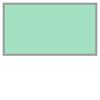

In [4]:
config = get_config()
print('Root dir: ', config['root_dir'])
raster_path = config['root_dir'] / 'raw_data' / 'hazard_maps_timesteps_tif' / 'timestep_8.tif'
# raster_path = config['root_dir'] / 'data' / 'test_samples' / 'test_hazard_timesteps' / 'Frag_timesteps_test1.tif'

with rio_open(raster_path) as src:
    raster_bounds = box(*src.bounds)
    raster_crs = src.crs

extent_gdf = gpd.GeoDataFrame(geometry=[raster_bounds], crs=raster_crs).to_crs(epsg=4326)
extent_polygon = extent_gdf.geometry.iloc[0]
extent_polygon


In [5]:
# Extract amenities (both point and polygon features) within the extent.
# The tag filter above casts a wide net; classification (below) narrows
# this down to exactly the four functional categories used by PowerPath.
amenities = osmnx.features_from_polygon(extent_polygon, tags=osm_tags)
amenities = amenities.reset_index()
amenities.geom_type.value_counts()


Point      1949
Polygon     704
Name: count, dtype: int64

In [6]:
# Split into point and polygon geometries
point_amenities = amenities[amenities.geom_type == "Point"].copy()
polygon_amenities = amenities[amenities.geom_type.isin(["Polygon", "MultiPolygon"])].copy()

print(f"Points: {len(point_amenities)}, Polygons: {len(polygon_amenities)}")


Points: 1949, Polygons: 704


In [7]:
# Some facilities are mapped as both a point and a polygon (e.g. a node inside
# a building outline). Drop the point in that case and keep the polygon - but
# only if they're actually the *same* facility (matching name, or an unnamed
# polygon representing the same bare building outline). Containment alone
# isn't enough: a point can legitimately sit inside an unrelated polygon
# (e.g. a school building inside a shared campus with a differently-named
# school), and dropping it there would silently lose a real facility.
overlap = gpd.sjoin(
    point_amenities[["name", "geometry"]],
    polygon_amenities[["name", "geometry"]].rename(columns={"name": "name_right"}),
    how="left",
    predicate="within",
)


def _is_same_facility(row):
    if pd.isna(row["index_right"]):
        return False
    polygon_name = row["name_right"]
    if pd.isna(polygon_name):
        return True
    return str(row["name"]).strip().lower() == str(polygon_name).strip().lower()


overlap["is_duplicate"] = overlap.apply(_is_same_facility, axis=1)
duplicate_point_idx = overlap.groupby(overlap.index)["is_duplicate"].any()
duplicate_point_idx = duplicate_point_idx[duplicate_point_idx].index
point_amenities = point_amenities.drop(index=duplicate_point_idx)

print(f"Points removed as duplicates of a polygon: {len(duplicate_point_idx)}")
print(f"Remaining points: {len(point_amenities)}, Polygons: {len(polygon_amenities)}")


Points removed as duplicates of a polygon: 111
Remaining points: 1838, Polygons: 704


## Assign the PowerPath asset `type`

Classify each facility into one of the four healthcare function categories using the mapping below, checking both the primary `amenity=*` tag and the secondary `healthcare=*` tag (OSM uses both to describe the same kinds of facilities). This mirrors the taxonomy documented in `config['service_node_config']['taxonomy']`.

Facilities whose tags fall outside this taxonomy (e.g. `healthcare=dentist`, `healthcare=laboratory`, `healthcare=alternative`) are dropped — PowerPath does not track additional healthcare categories beyond EMS / Hospitals / Primary & Community Care / Pharmacies.

**Assumption / tag ambiguity**: `health_centre` and `drugstore` are not standard OSM tag *values* — the closest real-world OSM equivalents are `amenity=clinic` + `healthcare=centre` (community health centre) and `shop=chemist` respectively. Both are handled by the mapping below (`"centre"` and `"chemist"` keys).

In [8]:
# Function-category taxonomy: raw OSM amenity/healthcare tag value -> PowerPath
# function category. Kept in sync with config['service_node_config']['taxonomy'].
TYPE_MAPPING = {
    "ambulance_station": "ems",
    "hospital": "hospital",
    "clinic": "primary_care",
    "doctors": "primary_care",
    "centre": "primary_care",  # healthcare=centre (community health centre)
    "pharmacy": "pharmacy",
    "chemist": "pharmacy",  # shop=chemist / healthcare=chemist ("drugstore" equivalent)
    "supermarket": "supermarket",
    "school": "school",  # placeholder; refined into school/school_so/school_vso below
    "childcare": "school",  # some schools are tagged amenity=childcare in OSM; DUO matching downstream filters out genuine daycare-only facilities
}

CATEGORY_LABELS = {
    "ems": "EMS",
    "hospital": "Hospitals",
    "primary_care": "Primary Care",
    "pharmacy": "Pharmacies",
    "supermarket": "Supermarkets",
}


def classify_type(row):
    """Map a raw OSM amenity/healthcare tag value to a PowerPath function
    category. Checks `amenity=*`
    first, then falls back to the secondary `healthcare=*` tag. Returns None
    for tag values outside this taxonomy, which are dropped.
    """
    amenity = row.get("amenity")
    if amenity in TYPE_MAPPING:
        return TYPE_MAPPING[amenity]

    emergency_tag = row.get("emergency")
    if emergency_tag in TYPE_MAPPING:
        return TYPE_MAPPING[emergency_tag]
    
    healthcare_tag = row.get("healthcare")
    if healthcare_tag in TYPE_MAPPING:
        return TYPE_MAPPING[healthcare_tag]

    shop_tag = row.get("shop")
    if shop_tag in TYPE_MAPPING:
        return TYPE_MAPPING[shop_tag]
    
    return None


point_amenities["type"] = point_amenities.apply(classify_type, axis=1)
polygon_amenities["type"] = polygon_amenities.apply(classify_type, axis=1)


In [9]:

dropped_points = point_amenities["type"].isna().sum()
dropped_polygons = polygon_amenities["type"].isna().sum()
if dropped_points or dropped_polygons:
    print(
        f"Dropping {dropped_points + dropped_polygons} facilities with tags outside "
        "the EMS/hospital/primary_care/pharmacy taxonomy "
        "(e.g. dentist, laboratory, alternative medicine)."
    )
    # detailed list of what will be dropped
    dropped_facilities = pd.concat([
        point_amenities[point_amenities["type"].isna()],
        polygon_amenities[polygon_amenities["type"].isna()]
    ], ignore_index=True)
    print("Dropped facilities:")
    print(dropped_facilities[["name", "healthcare", "amenity"]].to_string(index=False))
point_amenities = point_amenities.dropna(subset=["type"])
polygon_amenities = polygon_amenities.dropna(subset=["type"])


Dropping 550 facilities with tags outside the EMS/hospital/primary_care/pharmacy taxonomy (e.g. dentist, laboratory, alternative medicine).
Dropped facilities:
                                                               name              healthcare         amenity
                                                     Dental Clinics                 dentist         dentist
                                          Medisch Centrum "De Boei"                     yes             NaN
                                                            TopDent                 dentist         dentist
                                      Ypenburgse Tandartsenpraktijk                 dentist         dentist
                       Tandprothetische praktijk Bob Koetsenruijter                 dentist             NaN
                                                                NaN                 dentist         dentist
                                                        Orthocenter                 

In [10]:
assets = gpd.GeoDataFrame(
    pd.concat([point_amenities, polygon_amenities], ignore_index=True)
).drop_duplicates(subset=["name"]).sort_values("name")

print(f"Selected {len(assets)} assets")
assets["type"].value_counts()


Selected 1473 assets


type
school          800
primary_care    322
pharmacy        162
supermarket     158
hospital         22
ems               9
Name: count, dtype: int64

## Schools: pupil-count join

OSM only tells us a school's location and name, not whether it serves children under 15. We join matched schools to DUO's `leerlingen per schoolvestiging` dataset (pupil counts per school site) and split them by `SOORT_VESTIGING` into three independent weighted-Voronoi functions: `school` (BO/SBO, regular primary), `school_so` (SO, special education) and `school_vso` (VSO and combined SO/VSO sites, secondary-aged special education). Only CSV rows with >0 pupils in the most recent year are used; schools that don't match a CSV row are dropped.

Matching is name-based (DUO has no coordinates): normalize both OSM `name` and DUO `NAAM_VESTIGING`, restrict candidates to the DUO municipality the hazard extent overlaps, then match exact-normalized first and fall back to `difflib` fuzzy matching. Where multiple DUO rows share the same (municipality, normalized name) -- e.g. two branches of the same school -- DUO's lack of addresses means we can't tell which OSM point is which branch, so we assign the mean pupil count across candidates.

In [11]:
# Municipalities the hazard extent overlaps, used below to restrict DUO
# candidate rows and avoid matching a school to a same-named school elsewhere
# in the Netherlands.
extent_28992 = gpd.GeoDataFrame(geometry=[raster_bounds], crs=raster_crs).to_crs(epsg=28992)
gemeenten = gpd.read_file(
    config['root_dir'] / 'data' / 'utilities' / 'bestuurlijkegrenzen.gpkg', layer='gemeenten'
)
overlapping_gemeenten = gemeenten[gemeenten.intersects(extent_28992.geometry.iloc[0])]
extent_municipalities = set(overlapping_gemeenten['gemeentenaam'].str.upper())
print(f"Municipalities overlapping the extent ({len(extent_municipalities)}): {sorted(extent_municipalities)}")

Municipalities overlapping the extent (18): ["'S-GRAVENHAGE", 'BRIELLE', 'DELFT', 'LANSINGERLAND', 'LEIDSCHENDAM-VOORBURG', 'MAASSLUIS', 'MIDDEN-DELFLAND', 'PIJNACKER-NOOTDORP', 'RIJSWIJK', 'ROTTERDAM', 'SCHIEDAM', 'VLAARDINGEN', 'VOORSCHOTEN', 'WASSENAAR', 'WESTLAND', 'WESTVOORNE', 'ZOETERMEER', 'ZOETERWOUDE']


In [12]:
# DUO pupil counts per school site, filtered to schools serving children <15
# and with >0 pupils in the most recent year.
DUO_CSV_PATH = Path(r"C:\repos\powerpath\data\population\06.-historisch-overzicht-aantal-leerlingen-per-schoolvestiging.csv")

SOORT_VESTIGING_TO_FUNCTION = {
    "BO": "school",        # regular primary education
    "SBO": "school",       # special primary education, same age range as BO
    "SO": "school_so",     # standalone special education (ambiguous age range, included per project decision)
    "VSO": "school_vso",   # special secondary education
    "SO/VSO": "school_vso",  # combined site; lumped with VSO since it mixes in secondary-aged pupils
}

duo = pd.read_csv(DUO_CSV_PATH, sep=";", encoding="latin1")
duo["type"] = duo["SOORT_VESTIGING"].map(SOORT_VESTIGING_TO_FUNCTION)
duo = duo[duo["type"].notna()]
duo = duo[duo["GEMEENTENAAM_VESTIGING"].str.upper().isin(extent_municipalities)]
duo["pupils"] = pd.to_numeric(duo["LEERLINGEN_2025"], errors="coerce")
duo = duo[duo["pupils"] > 0]
print(f"DUO school sites after municipality/type/pupil filtering: {len(duo)}")
duo["type"].value_counts()

DUO school sites after municipality/type/pupil filtering: 670


type
school        592
school_vso     56
school_so      22
Name: count, dtype: int64

In [13]:
# Name normalization: lowercase, strip punctuation, drop common Dutch
# school-type prefixes/filler words and trailing branch-numeral suffixes
# (e.g. "De Gantel I"/"De Gantel II" -> "gantel", not "gantel i"/"gantel ii")
# that differ between OSM and DUO naming. A trailing "school" *substring*
# (not just a standalone "school" token) is also stripped from any token,
# since it is glued onto an identifying name inconsistently between sources
# (OSM "Duinoordschool" vs DUO "Montessorischool"/"Basisschool").
# Dutch school-type/denomination abbreviations, compiled from a scan of
# all short (2-5 char) ALL-CAPS tokens across the DUO corpus. Tokens that
# look like part of an identifying name (saint/person names, titles,
# initials, e.g. OLV, ARK, BAVO, DR, ST, PROF, PWA, XXIII) are
# deliberately excluded - those must survive normalization, not be
# stripped as filler.
SCHOOL_NAME_FILLER_WORDS = {
    "bs", "obs", "cbs", "pcbs", "rkbs", "kbs", "ibs", "jenaplan",
    "school", "de", "het", "'t",
    "ikc", "kindcentrum", "integraal", "kc", "pc", "bao", "isl",
    "rk", "chr", "ssbo", "sbo", "ssvo", "vso", "so", "sws", "pcbo",
    "lom", "pro", "gbs", "pcb", "opb", "cns", "zmlk", "zmok", "sgm",
    "oec", "icbs", "mlk", "ckc", "mkc", "blo", "sam", "jji", "rkb",
    "mbs", "vbo", "ikec", "gji", "ekc", "hkc", "nh", "ojs", "nbs",
    "rec", "bo", "svo", "cms", "csbo", "beo",
    "basisschool", "basissch",
}
ROMAN_NUMERAL_RE = re.compile(r"^(i|ii|iii|iv|v|vi|vii|viii|ix|x)$")
SCHOOL_SUFFIX_RE = re.compile(r"^(.+)school$")


# Dutch ordinal/abbreviation word-choice variants seen between OSM and
# DUO for the same school (e.g. DUO "1e Ned Montessorischool" vs OSM
# "Eerste Nederlandse Montessorischool") - these are lexical equivalences,
# not spelling typos, so no fuzziness threshold can bridge them; they
# need explicit token-level canonicalization instead.
ORDINAL_WORD_MAP = {"1e": "eerste", "2e": "tweede", "3e": "derde", "4e": "vierde"}
WORD_SYNONYMS = {"ned": "nederlandse"}
# Collapses letter-by-letter abbreviations like "R.K." into one token
# ("rk") before punctuation is stripped, so they can hit the single-word
# filler entries below ("rk", "chr", ...) instead of surviving as
# meaningless leftover single letters ("r", "k").
LETTER_ABBREV_RE = re.compile(r"\b(?:[A-Za-z]\.){2,}")


def normalize_school_name(name):
    name = str(name).replace('"', "").replace("'", "")
    name = LETTER_ABBREV_RE.sub(lambda m: m.group(0).replace(".", ""), name)
    name = name.lower()
    name = re.sub(r"[^a-z0-9\s]", " ", name)
    tokens = [ORDINAL_WORD_MAP.get(t, WORD_SYNONYMS.get(t, t)) for t in name.split()]
    tokens = [t for t in tokens if t not in SCHOOL_NAME_FILLER_WORDS]
    tokens = [SCHOOL_SUFFIX_RE.sub(r"\1", t) for t in tokens]
    if len(tokens) > 1 and ROMAN_NUMERAL_RE.match(tokens[-1]):
        tokens = tokens[:-1]
    return " ".join(tokens).strip()


schools = point_amenities[point_amenities["type"] == "school"]
schools = pd.concat([schools, polygon_amenities[polygon_amenities["type"] == "school"]], ignore_index=True)
schools = gpd.GeoDataFrame(schools, crs=point_amenities.crs)
schools["norm_name"] = schools["name"].apply(normalize_school_name)
# OSM sometimes carries the DUO-matching name in alt_name instead of (or as
# well as) name (e.g. "Sint Bernardus" with alt_name "Sint Bernardusschool").
# Tried as a fallback candidate when the primary name doesn't match.
schools["alt_norm_name"] = (
    schools["alt_name"].apply(normalize_school_name) if "alt_name" in schools.columns else ""
)
schools_28992 = schools.to_crs(epsg=28992)
schools_with_muni = gpd.sjoin(
    schools_28992, overlapping_gemeenten[["gemeentenaam", "geometry"]], how="left", predicate="intersects"
)
schools["muni"] = schools_with_muni["gemeentenaam"].str.upper().values

duo["norm_name"] = duo["NAAM_VESTIGING"].apply(normalize_school_name)
duo_by_muni_name = {}
for _, row in duo.iterrows():
    duo_by_muni_name.setdefault((row["GEMEENTENAAM_VESTIGING"].upper(), row["norm_name"]), []).append(row)
duo_names_by_muni = {}
for muni, norm_name in duo_by_muni_name:
    duo_names_by_muni.setdefault(muni, []).append(norm_name)

# Pass 1: find each OSM school's matched DUO (municipality, normalized name)
# key, exact first then difflib fuzzy fallback. Tried against norm_name, and
# if that fails entirely, retried against alt_norm_name (OSM's alt_name tag
# sometimes carries the DUO-matching form, e.g. "Sint Bernardusschool").
def _match_name(muni, norm_name):
    """Return (key, match_type) or (None, None) for a single normalized name."""
    if not norm_name:
        return None, None
    key = (muni, norm_name)
    if key in duo_by_muni_name:
        return key, "exact"
    osm_tokens = norm_name.split()
    prefix_candidates = [
        n for n in duo_names_by_muni.get(muni, [])
        if n and len(n.split()) < len(osm_tokens) and osm_tokens[: len(n.split())] == n.split()
    ]
    if prefix_candidates:
        best = max(prefix_candidates, key=lambda n: len(n.split()))
        return (muni, best), "prefix"
    close = difflib.get_close_matches(norm_name, duo_names_by_muni.get(muni, []), n=1, cutoff=0.85)
    if close:
        return (muni, close[0]), "fuzzy"
    # Second, looser fuzzy pass (cutoff 0.70) for names a stringent match
    # would miss (e.g. compounded typos on top of other differences).
    # Flagged as its own match_type since false-positive risk is higher -
    # surfaced in fuzzy_match_rows for manual review, same as "fuzzy".
    loose = difflib.get_close_matches(norm_name, duo_names_by_muni.get(muni, []), n=1, cutoff=0.70)
    if loose:
        return (muni, loose[0]), "fuzzy_loose"
    return None, None


osm_matches = []  # (row, matched_key, match_type) or (row, None, None) if unmatched
for _, row in schools.iterrows():
    key, match_type = _match_name(row["muni"], row["norm_name"])
    if key is None and row["alt_norm_name"]:
        key, match_type = _match_name(row["muni"], row["alt_norm_name"])
    osm_matches.append((row, key, match_type))

# Pass 2: group OSM schools by their matched DUO key, and fair-share that
# key's total pupil count across however many OSM features matched it.
# This handles multiplicity on *either* side without double-counting or
# arbitrarily dropping one: e.g. 2 DUO branches sharing 1 OSM building
# (mean across candidates) just as much as 1 DUO entry shared by 2 OSM
# buildings (e.g. "De Gantel I"/"De Gantel II" splitting one DUO pupil count).
osm_rows_by_key = {}
for row, key, match_type in osm_matches:
    if key is not None:
        osm_rows_by_key.setdefault(key, []).append((row, match_type))

exact_count = fuzzy_count = prefix_count = loose_count = unmatched_count = 0
matched_rows = []
fuzzy_match_rows = []
unmatched_rows = []
for row, key, match_type in osm_matches:
    if key is None:
        unmatched_count += 1
        unmatched_rows.append({
            "osm_name": row["name"],
            "muni": row["muni"],
            "norm_name": row["norm_name"],
        })
        continue
    exact_count += (match_type == "exact")
    fuzzy_count += (match_type == "fuzzy")
    prefix_count += (match_type == "prefix")
    loose_count += (match_type == "fuzzy_loose")
    candidates = duo_by_muni_name[key]
    n_osm_sharing = len(osm_rows_by_key[key])
    pupils = sum(c["pupils"] for c in candidates) / n_osm_sharing
    if match_type in ("fuzzy", "prefix", "fuzzy_loose"):
        fuzzy_match_rows.append({
            "osm_name": row["name"],
            "csv_name": candidates[0]["NAAM_VESTIGING"],
            "muni": row["muni"],
            "match_type": match_type,
            "n_candidates": len(candidates),
            "n_osm_sharing": n_osm_sharing,
            "pupils": pupils,
        })
    matched_rows.append({
        "geometry": row["geometry"],
        "name": row["name"],
        "type": candidates[0]["type"],
        "pupils": pupils,
    })

print(f"Schools matched to DUO data: {exact_count} exact, {prefix_count} prefix, {fuzzy_count} fuzzy, {loose_count} loose-fuzzy, {unmatched_count} unmatched (dropped)")
school_assets = gpd.GeoDataFrame(matched_rows, crs=schools.crs)
matched_duo_keys = set(osm_rows_by_key.keys())
school_assets["type"].value_counts()

Schools matched to DUO data: 347 exact, 31 prefix, 30 fuzzy, 60 loose-fuzzy, 541 unmatched (dropped)


type
school        422
school_vso     35
school_so      11
Name: count, dtype: int64

In [14]:
# For manual review: every fuzzy match (where OSM and DUO names differ),
# every dropped/unmatched OSM school, and every in-scope DUO school site that
# never got matched to an OSM feature at all.
fuzzy_matches_df = pd.DataFrame(fuzzy_match_rows).sort_values("muni")
unmatched_schools_df = pd.DataFrame(unmatched_rows).sort_values("muni")
unmatched_duo_rows = [
    {
        "csv_name": row["NAAM_VESTIGING"],
        "muni": row["GEMEENTENAAM_VESTIGING"].upper(),
        "bucket": row["type"],
        "pupils": row["pupils"],
    }
    for _, row in duo.iterrows()
    if (row["GEMEENTENAAM_VESTIGING"].upper(), row["norm_name"]) not in matched_duo_keys
]
unmatched_duo_df = pd.DataFrame(unmatched_duo_rows).sort_values("muni")
print(f"Fuzzy matches: {len(fuzzy_matches_df)}")
print(f"Unmatched OSM schools (dropped): {len(unmatched_schools_df)}")
print(f"Unmatched DUO school sites (no OSM feature found): {len(unmatched_duo_df)}")

Fuzzy matches: 121
Unmatched OSM schools (dropped): 541
Unmatched DUO school sites (no OSM feature found): 277


In [15]:
fuzzy_matches_df

,osm_name,csv_name,muni,match_type,n_candidates,n_osm_sharing,pupils
1,Maris College Statenkwartier,IC BS Statenkwartier,'S-GRAVENHAGE,fuzzy_loose,1,1,273.0
3,Montessorischool Leidschenveen,Montessorisch Leidschenv,'S-GRAVENHAGE,fuzzy,1,1,387.0
4,Montessorischool Waalsdorp,Montessorisch Waalsdorp,'S-GRAVENHAGE,fuzzy,1,1,296.0
5,Bernardusschool Locatie SO,Bernardusschool,'S-GRAVENHAGE,prefix,1,1,145.0
8,Pleysier College Zefier,Pleysier College Westerbeek,'S-GRAVENHAGE,fuzzy_loose,1,3,100.0
...,...,...,...,...,...,...,...
99,Prins Willem-Alexanderschool,Pr Willem Alexandersch,WESTLAND,fuzzy,1,2,203.5
2,Passe Partout,Passe Partout Mont.school,ZOETERMEER,fuzzy_loose,1,2,66.0
46,PassePartout,Passe Partout Mont.school,ZOETERMEER,fuzzy_loose,1,2,66.0
62,Praktijkcollege Zoetermeer,Kentalis College Zoetermeer,ZOETERMEER,fuzzy_loose,1,1,69.0


In [16]:
unmatched_schools_df

,osm_name,muni,norm_name
1,Junior School Leidschenveen,'S-GRAVENHAGE,junior leidschenveen
3,Openbare Basisschool Galvani,'S-GRAVENHAGE,openbare galvani
12,Haags Taalplein,'S-GRAVENHAGE,haags taalplein
14,Janinerakkers,'S-GRAVENHAGE,janinerakkers
15,MasonRakkers,'S-GRAVENHAGE,masonrakkers
...,...,...,...
459,De Edelsteen,ZOETERMEER,edelsteen
462,NaN,ZOETERMEER,nan
504,NaN,ZOETERMEER,nan
506,Alfrink College,ZOETERMEER,alfrink college


In [17]:
unmatched_schools_df[
    unmatched_schools_df["osm_name"].str.contains("Meinderts", case=False, na=False, regex=False)
]

,osm_name,muni,norm_name


In [18]:
unmatched_duo_df

,csv_name,muni,bucket,pupils
6,SBO,'S-GRAVENHAGE,school,83.0
34,Schoolvereniging Wolters,'S-GRAVENHAGE,school,432.0
35,Bs Haagsche School Ver,'S-GRAVENHAGE,school,705.0
53,Basissch De Jonge Wereld,'S-GRAVENHAGE,school,242.0
54,Bs Grote Beer,'S-GRAVENHAGE,school,353.0
...,...,...,...,...
253,Florence Nightingale,ZOETERMEER,school,584.0
256,Oranjerie,ZOETERMEER,school,424.0
260,Yunus Emre,ZOETERMEER,school,296.0
49,St Bernardusschool,ZOETERWOUDE,school,265.0


In [19]:
# Replace the generic "school" placeholder rows with the matched/typed school
# assets, and give non-school assets an empty pupils column for a uniform schema.
assets = assets[assets["type"] != "school"].copy()
assets["pupils"] = pd.NA
assets = gpd.GeoDataFrame(pd.concat([assets, school_assets], ignore_index=True))

# Weighted-Voronoi weight basis: bound raw pupil counts to [100, 1000] before
# use. Pupil counts span a ~20x range (e.g. 14 to 2000+), and that raw spread
# is large enough relative to inter-school spacing that any single scale
# factor either makes nearby, very unevenly sized schools swallow each other
# entirely or makes weighting negligible everywhere else. Clamping keeps
# relative capacity differences meaningful without the extreme tail driving
# pathological domination.
assets["pupils_weight"] = pd.to_numeric(assets["pupils"], errors="coerce").clip(lower=100, upper=1000)

print(f"Total assets after school join: {len(assets)}")
assets["type"].value_counts()

Total assets after school join: 1141


type
school          422
primary_care    322
pharmacy        162
supermarket     158
school_vso       35
hospital         22
school_so        11
ems               9
Name: count, dtype: int64

In [20]:
SCHOOL_LABELS = {
    "school": "Schools (BO/SBO)",
    "school_so": "Schools (SO)",
    "school_vso": "Schools (VSO)",
}

In [21]:
# Validation: print facility counts per function category so the
# taxonomy can be verified quickly as part of the notebook workflow.
print("Asset counts")
print()
counts = assets["type"].value_counts()
for category, label in {**CATEGORY_LABELS, **SCHOOL_LABELS}.items():
    print(f"{label}: {int(counts.get(category, 0))}")

Asset counts

EMS: 9
Hospitals: 22
Primary Care: 322
Pharmacies: 162
Supermarkets: 158
Schools (BO/SBO): 422
Schools (SO): 11
Schools (VSO): 35


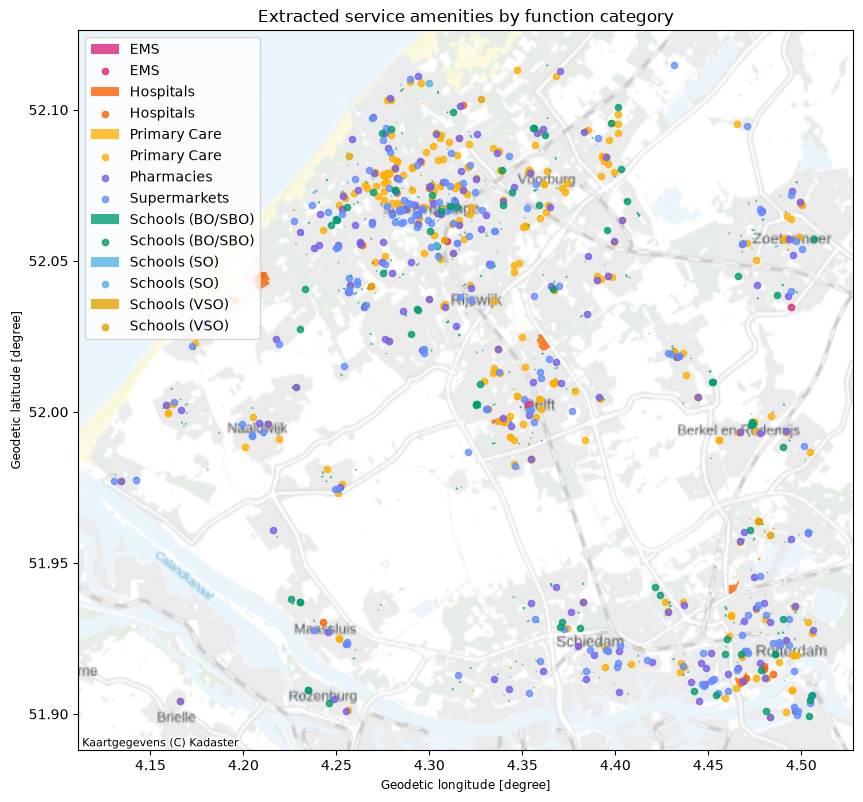

In [22]:
# Plot all mapped amenities, coloured by function category
fig, ax = plt.subplots(figsize=(10, 10))
cat_colors = {
    'ems': "#DC267F", 'hospital': '#FE6100', 'primary_care': '#FFB000',
    'pharmacy': '#785EF0', 'supermarket': "#648FFF",
    'school': '#009E73', 'school_so': '#56B4E9', 'school_vso': '#E69F00',
}
for category, color in cat_colors.items():
    subset = assets[assets["type"] == category]
    if len(subset):
        subset.plot(ax=ax, color=color, alpha=0.8, markersize=20, label={**CATEGORY_LABELS, **SCHOOL_LABELS}[category])
ctx.add_basemap(ax, source=ctx.providers.nlmaps.grijs, crs=assets.crs.to_string())
ax.set_title("Extracted service amenities by function category")
ax.legend()
plt.show()

In [23]:
output_path = config['osm_asset_dir'] / "osm_assets.gpkg"
output_path.parent.mkdir(parents=True, exist_ok=True)
assets[['geometry', 'type', 'name', 'pupils', 'pupils_weight']].to_file(output_path, driver="GPKG")

assets[['name', 'type', 'pupils', 'pupils_weight']]

,name,type,pupils,pupils_weight
0,'t Hoekje,supermarket,<NA>,NaN
1,A&M Supermarkt,supermarket,<NA>,NaN
2,A.P.M.T. Bruijs huisarts,primary_care,<NA>,NaN
3,ABC,supermarket,<NA>,NaN
4,ABC XXL,supermarket,<NA>,NaN
...,...,...,...,...
1136,Het Landje,school,319.0,319.000000
1137,Montessorischool Maassluis,school,189.0,189.000000
1138,Kindcentrum De Regenboog,school,134.0,134.000000
1139,Jacob Maris,school,195.0,195.000000


In [24]:
print(assets[["name", "type", "healthcare", "amenity", "shop"]].to_string(index=False))

                                                  name         type       healthcare       amenity        shop
                                             't Hoekje  supermarket              NaN           NaN supermarket
                                        A&M Supermarkt  supermarket              NaN           NaN supermarket
                              A.P.M.T. Bruijs huisarts primary_care           doctor       doctors         NaN
                                                   ABC  supermarket              NaN           NaN supermarket
                                               ABC XXL  supermarket              NaN           NaN supermarket
                                                  ALDI  supermarket              NaN           NaN supermarket
                                              Aaruksha  supermarket              NaN           NaN supermarket
                                       Akelei apotheek     pharmacy         pharmacy      pharmacy         NaN
 

## Weighted-Voronoi school service areas

Sanity-check the extracted schools by computing their weighted-Voronoi (power-diagram) catchments, reusing the same function `src.simulation`/`src.adaptation` use at runtime.

school: 367 cells
school_vso: 34 cells
school_so: 11 cells


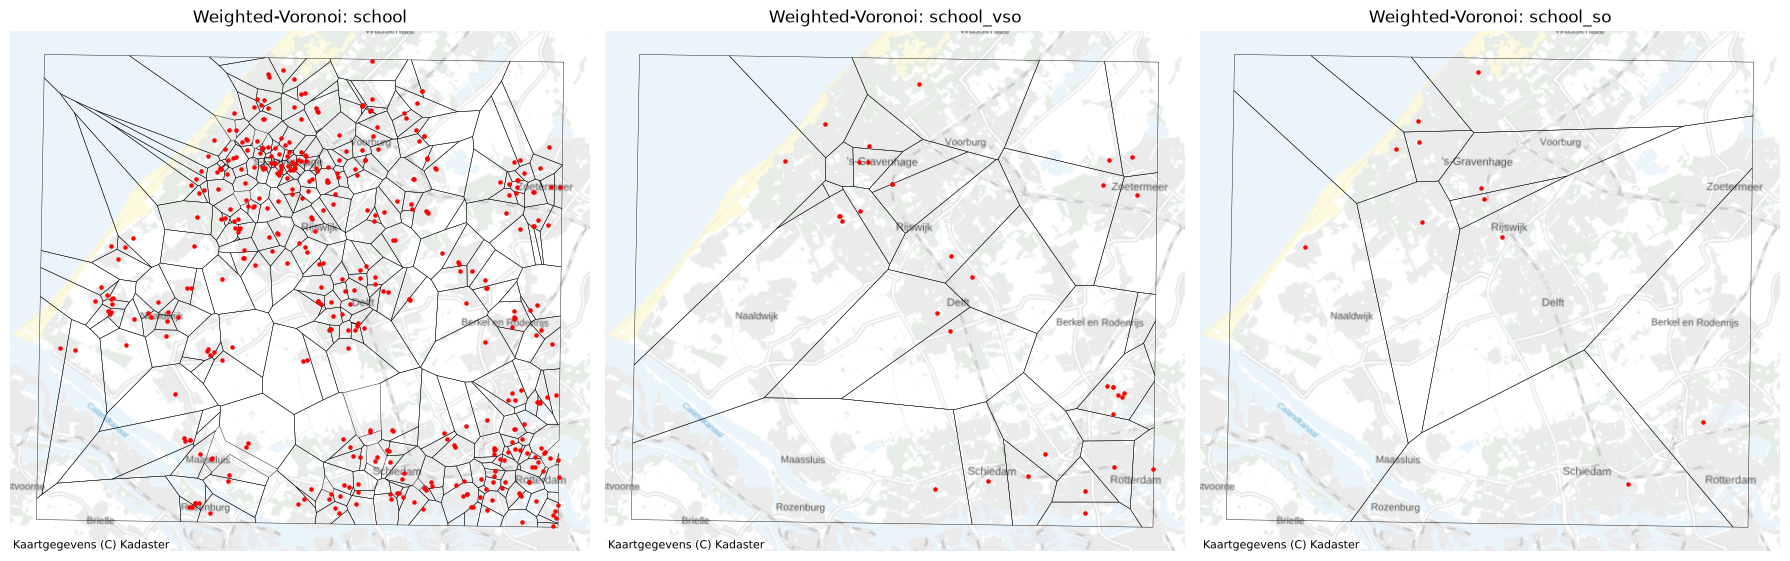

In [25]:
from src.impacts import create_weighted_voronoi_for_asset_type
from config import SCHOOL_WEIGHTED_VORONOI_SCALE_FACTORS

school_voronoi_gdfs = {
    asset_type: create_weighted_voronoi_for_asset_type(
        assets,
        asset_type,
        weight_column="pupils_weight",
        boundary=extent_28992.geometry.iloc[0],
        weight_scale_factor=scale_factor,
    )
    for asset_type, scale_factor in SCHOOL_WEIGHTED_VORONOI_SCALE_FACTORS.items()
}
for asset_type, voronoi_gdf in school_voronoi_gdfs.items():
    print(f"{asset_type}: {len(voronoi_gdf)} cells")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

school_assets_projected = assets[
    assets["type"].isin(SCHOOL_WEIGHTED_VORONOI_SCALE_FACTORS)
].to_crs(epsg=28992)

for ax, (asset_type, voronoi_gdf) in zip(axes, school_voronoi_gdfs.items()):
    voronoi_gdf.plot(ax=ax, edgecolor="black", linewidth=0.3, facecolor="none")
    school_assets_projected[
        school_assets_projected["type"] == asset_type
    ].centroid.plot(ax=ax, color="red", markersize=5)

    ax.set_title(f"Weighted-Voronoi: {asset_type}")
    ax.set_axis_off()
    ctx.add_basemap(ax, source=ctx.providers.nlmaps.grijs, crs=voronoi_gdf.crs.to_string())

plt.tight_layout()
plt.show()


In [26]:

import numpy as np
vso = assets[assets["type"] == "school_vso"].to_crs(epsg=28992).copy()
vso["x"] = vso.geometry.centroid.x
vso["y"] = vso.geometry.centroid.y
mean_w = vso["pupils"].mean()
vso["weight"] = (vso["pupils"] / mean_w) * 1e6
vso[["name", "pupils", "weight", "x", "y"]].sort_values("pupils").to_csv(
    r"C:\repos\powerpath\powerpath\_tmp_vso_weights.csv", index=False
)
print(f"n={len(vso)}, mean pupils={mean_w:.1f}, weight range=[{vso['weight'].min():.0f}, {vso['weight'].max():.0f}]")

# pairwise squared distances vs weight differences, to see how often weight
# diff exceeds squared distance (meaning the lower-weight site in the pair
# can be partly/fully dominated well beyond "local" neighbor range)
coords = vso[["x", "y"]].to_numpy()
weights = vso["weight"].to_numpy()
n = len(vso)
dominance_events = 0
total_pairs = 0
for i in range(n):
    for j in range(n):
        if i == j:
            continue
        total_pairs += 1
        dist2 = np.sum((coords[i] - coords[j]) ** 2)
        wdiff = weights[j] - weights[i]
        if wdiff > dist2:
            dominance_events += 1
print(f"pairs where weight diff > dist^2 (i fully excluded from own location by j): {dominance_events}/{total_pairs}")


n=35, mean pupils=114.7, weight range=[122012, 2492530]
pairs where weight diff > dist^2 (i fully excluded from own location by j): 18/1190


In [27]:

import numpy as np
from scipy.spatial import cKDTree

results = {}
for asset_type in ["school", "school_vso", "school_so"]:
    sub = assets[assets["type"] == asset_type].to_crs(epsg=28992).copy()
    sub["x"] = sub.geometry.centroid.x
    sub["y"] = sub.geometry.centroid.y
    coords = sub[["x", "y"]].to_numpy()
    pupils = sub["pupils"].to_numpy(dtype=float)
    ratio = pupils / pupils.mean()

    tree = cKDTree(coords)
    # query 2 nearest (including self at dist 0), take the real nearest neighbor
    dists, idxs = tree.query(coords, k=2)
    nn_dist = dists[:, 1]
    nn_idx = idxs[:, 1]
    nn_dist2 = nn_dist ** 2
    nn_ratio_diff = np.abs(ratio - ratio[nn_idx])

    median_nn_dist2 = float(np.median(nn_dist2))
    median_ratio_diff = float(np.median(nn_ratio_diff[nn_ratio_diff > 0]))
    candidate_scale = median_nn_dist2 / median_ratio_diff if median_ratio_diff else None

    results[asset_type] = {
        "n": len(sub),
        "median_nn_dist2": median_nn_dist2,
        "median_ratio_diff": median_ratio_diff,
        "candidate_scale_factor": candidate_scale,
        "ratio_min": float(ratio.min()),
        "ratio_max": float(ratio.max()),
    }
    print(asset_type, results[asset_type])


school {'n': 422, 'median_nn_dist2': 76660.71129672328, 'median_ratio_diff': 0.4997979076390914, 'candidate_scale_factor': 153383.41782751255, 'ratio_min': 0.12957723531383847, 'ratio_max': 6.636205551430156}
school_vso {'n': 35, 'median_nn_dist2': 1303122.1760431584, 'median_ratio_diff': 0.45318725099601587, 'candidate_scale_factor': 2875460.8016424864, 'ratio_min': 0.12201195219123505, 'ratio_max': 2.4925298804780875}
school_so {'n': 11, 'median_nn_dist2': 4675032.41204703, 'median_ratio_diff': 0.3509471585244268, 'candidate_scale_factor': 13321186.105918096, 'ratio_min': 0.6360917248255233, 'ratio_max': 1.4147557328015952}


In [28]:

from src.impacts import create_weighted_voronoi_for_asset_type
vso_gdf, diag = create_weighted_voronoi_for_asset_type(
    assets, "school_vso", weight_column="pupils_weight",
    boundary=extent_28992.geometry.iloc[0],
    weight_scale_factor=SCHOOL_WEIGHTED_VORONOI_SCALE_FACTORS["school_vso"],
    return_diagnostics=True, use_cache=False,
)
print("empty_providers:", diag["empty_providers"])
print("provider_count:", diag["provider_count"], "cells:", len(vso_gdf))

# Check each cell contains its own generator point
vso_pts = assets.loc[vso_gdf["asset_id"]].to_crs(epsg=28992)
contains_own = [
    poly.contains(pt) or poly.touches(pt)
    for poly, pt in zip(vso_gdf.geometry, vso_pts.geometry.centroid)
]
print("cells NOT containing own generator:", contains_own.count(False), "/", len(contains_own))


empty_providers: [752]
provider_count: 35 cells: 34


cells NOT containing own generator: 8 / 34
